# Where should Blinkit open its next dark stores in Indore?

Blinkit ran 2,443 dark stores in June 2026 and keeps opening more, at roughly ₹2.5 crore of capex each. With
that much money going into every store, choosing where the next one goes is a capital allocation problem as
much as a logistics one. It also has to respect three limits at the same time: a fixed budget, a delivery
radius that keeps the ten-minute promise realistic, and a limit on how many orders one store can pick and pack
in a day.

This notebook models that decision for a single city. I set it up as a capacitated facility location problem
and solve it as a mixed-integer linear program (MILP), which chooses which sites to open and how to split each
locality's orders across them. I then compare it against a greedy heuristic, which is close to how the
decision gets made without a model. That comparison is the main result. On its own, the optimizer's output
would just be a number, with nothing to say whether it is good or bad.

## What is real and what I made up

Every number below is either taken from Eternal's public reporting or invented for this project. I keep the
two apart throughout, because a synthetic-data project is only believable if you can always tell which is
which.

### Disclosed figures

| Figure | Value | Source |
|---|---|---|
| Blinkit store count | 2,443 | Eternal Q1 FY27 (June 2026) |
| Capex per store, including warehousing | ~₹2.5 crore | Eternal, long-run assumption |
| Steady-state NOV per store per day | ~₹11 lakh | Eternal, steady-state target |
| Net working capital | ~12 days | Eternal |
| Target pre-tax ROCE | ~41.7% | Eternal, under the above assumptions |
| Network footprint | ~19 million sq ft across 300+ cities | Eternal |
| Inventory and spoilage loss | ~1.8% of NOV, "fairly asymptotic" | Eternal |
| Peer average delivery distance | ~1.7–1.8 km, FY26 | Zepto disclosure |

### Assumptions

No real order, rent, location or dispatch data was used. None of it is public at this level of detail.

| Assumption | Value | Why |
|---|---|---|
| City | Indore | Tier-2 city with little quick-commerce presence yet, so expansion is a real question |
| Localities | 35, real names, approximate coordinates | Enough spatial structure to matter, small enough to solve in seconds |
| Demand history | 90 days, 1 Sep to 29 Nov 2025 | Covers Diwali (20 Oct 2025), so the festive peak falls on its real date |
| Candidate sites | 50 | |
| Existing stores | 6 | Makes the decision incremental, as it is for Blinkit |
| Average order value | ~₹560 overall, higher in richer areas | Assumed; the capacity estimate depends on it |
| Store capacity | 1,200 to 2,400 orders per day | Derived, see below |
| Delivery radius | 2.5 km | Assumed, set a little above the 1.7–1.8 km peer average |
| Budget | ₹20 crore | Assumed, enough for about eight stores at the disclosed capex |

### Where the capacity number comes from

Store capacity isn't disclosed, so I derived it:

```
₹11,00,000 NOV per store per day  ÷  ~₹600 average order value  ≈  1,800 orders per store per day
```

The ₹11 lakh is Eternal's figure, but the ₹600 is my assumption, so 1,800 is only as reliable as that
assumption. At ₹500 a basket the result would be about 2,200, and at ₹700 about 1,570. For that reason the site
capacities in the data are spread between 1,200 and 2,400, not fixed at a precise-looking 1,800.

## Setup

If `DATABASE_URL` is set, the notebook runs against MySQL 8. Otherwise it uses a local SQLite file, which
needs no setup. Run `python generate_data.py` once before opening the notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

from src.db import get_engine, load_query, backend_name, describe_connection, is_weekend_expr
from src.geo import build_facilities, distance_matrix, feasible_mask, coverage_report, DEFAULT_RADIUS_KM
from src.baseline import greedy_network
from src.optimizer import (optimize_network, sensitivity_sweep, scenario_analysis,
                           relaxation_gap, round_relaxation)
from src.evaluate import compare
from src import plots

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110

BUDGET = 20e7          # Rs 20 crore
RADIUS_KM = DEFAULT_RADIUS_KM

engine = get_engine()
print(f"backend: {backend_name(engine)}")
print(f"target : {describe_connection(engine)}")

backend: SQLite
target : sqlite:///data/blinkit_sim.db


## Looking at the data in SQL

The first questions I want answered are about the data itself. Which localities order the most? Where is demand
going unserved? How does each area compare with others of similar income? SQL handles these well, so I ask
them in SQL against the database, not by pulling every row into pandas. Each query is saved as its own file
under `sql/queries/`, and each cell prints the query before running it.

### 1. Demand by locality

This is a plain aggregation with one detail that matters. Revenue is worked out day by day, multiplying each
day's orders by that day's average order value and only then summing. If I summed all the orders first and
multiplied by one overall average, every day would count equally regardless of how busy it was, and the
busiest days, which bring in the most money, would be under-counted.

In [2]:
q1 = load_query("01_demand_by_locality.sql")
print(q1.split("\n\n")[-1])

demand_by_locality = pd.read_sql(text(q1), engine)
demand_by_locality.head(10)

SELECT
    l.locality_id,
    l.locality_name,
    l.avg_household_income_tier,
    l.population_density,
    COUNT(*)                                        AS days_observed,
    SUM(d.order_count)                              AS total_orders,
    ROUND(AVG(d.order_count), 1)                    AS avg_orders_per_day,
    ROUND(AVG(d.avg_order_value), 2)                AS avg_order_value,
    ROUND(SUM(d.order_count * d.avg_order_value), 2) AS total_revenue
FROM demand AS d
JOIN localities AS l
    ON l.locality_id = d.locality_id
GROUP BY
    l.locality_id,
    l.locality_name,
    l.avg_household_income_tier,
    l.population_density
ORDER BY
    avg_orders_per_day DESC;



,locality_id,locality_name,avg_household_income_tier,population_density,days_observed,total_orders,avg_orders_per_day,avg_order_value,total_revenue
0,12,Palasia,high,25492.86,90,181043,2011.6,723.88,1.318891e+08
1,10,New Palasia,high,25685.21,90,180828,2009.2,726.50,1.318298e+08
2,25,LIG Colony,high,22117.81,90,160137,1779.3,727.20,1.169232e+08
3,11,Old Palasia,high,21537.63,90,156903,1743.4,724.05,1.140544e+08
4,24,MIG Colony,high,21291.66,90,155062,1722.9,721.71,1.122481e+08
5,2,Sarafa Bazar,mid,32064.45,90,150184,1668.7,560.82,8.464707e+07
6,14,Saket Nagar,high,19338.56,90,143280,1592.0,721.41,1.037868e+08
7,6,Malviya Nagar,mid,30100.66,90,142360,1581.8,559.46,8.012554e+07
8,4,Chhoti Gwaltoli,mid,29637.65,90,139963,1555.1,565.15,7.944909e+07
9,5,Sanyogitaganj,mid,28436.77,90,135782,1508.7,562.52,7.682595e+07


### 2. Where demand goes unserved

Here I ask the business question directly: which busy localities have no existing store within the delivery
radius? There is no geography type in either database, so the query writes out the haversine distance formula
by hand. I use the arcsine form because the arccosine version can fail for points only a few kilometres
apart. The cosine of such a small angle rounds to just above 1.0, which `ACOS` cannot accept. To exclude
localities that already have a store nearby I use `NOT EXISTS`, not a `LEFT JOIN` followed by a null check. The
database can then stop looking for a given locality as soon as it finds one nearby store, instead of pairing
every locality with every store first.

In [3]:
q2 = load_query("02_underserved_localities.sql")
print(q2.split("\n\n")[-1])

with engine.connect() as conn:
    underserved = pd.read_sql(text(q2), conn, params={"radius_km": RADIUS_KM})
underserved

WITH locality_demand AS (
    SELECT
        d.locality_id,
        AVG(d.order_count) AS avg_orders_per_day
    FROM demand AS d
    GROUP BY d.locality_id
)
SELECT
    l.locality_id,
    l.locality_name,
    l.avg_household_income_tier,
    ROUND(ld.avg_orders_per_day, 1) AS avg_orders_per_day,
    ROUND(l.population_density, 0)  AS population_density
FROM localities AS l
JOIN locality_demand AS ld
    ON ld.locality_id = l.locality_id
WHERE NOT EXISTS (
    SELECT 1
    FROM existing_stores AS s
    WHERE 2 * 6371.0 * ASIN(
              SQRT(
                  POWER(SIN((RADIANS(s.latitude) - RADIANS(l.latitude)) / 2), 2)
                  + COS(RADIANS(l.latitude)) * COS(RADIANS(s.latitude))
                  * POWER(SIN((RADIANS(s.longitude) - RADIANS(l.longitude)) / 2), 2)
              )
          ) <= :radius_km
)
ORDER BY ld.avg_orders_per_day DESC
LIMIT 10;



,locality_id,locality_name,avg_household_income_tier,avg_orders_per_day,population_density
0,27,Dewas Naka,high,745.3,7578.0
1,29,Bhawarkuan,low,669.2,14862.0
2,17,Bengali Square,mid,579.9,8893.0
3,26,Sukhliya,mid,503.0,7427.0
4,19,Bicholi Mardana,mid,386.8,5393.0
5,20,Nipania,mid,378.0,5295.0
6,32,Annapurna,low,354.3,6862.0
7,18,Kanadia Road,low,342.1,6636.0
8,30,Musakhedi,low,305.1,5699.0
9,34,Silicon City,low,250.9,4551.0


### 3. Ranking within income tier

I want each locality's rank relative to the others in its own income tier. A `GROUP BY` would collapse the
localities into one row per tier and lose them, so this needs a window function. I also chose not to rank on
total orders, which would mostly show that big localities are big. Dividing orders by population density
shows which areas order a lot for their size.

In [4]:
q3 = load_query("03_rank_within_income_tier.sql")
print(q3.split("\n\n")[-1])

tier_ranks = pd.read_sql(text(q3), engine)
tier_ranks[tier_ranks["rank_in_tier"] <= 3]

    -- A second window over the same partition, this time an aggregate rather
    -- than a ranking. Because it keeps every row, each locality can be compared
    -- against its own tier's average on the same line -- something GROUP BY
    -- would need a self-join to achieve.
    ROUND(
        AVG(avg_orders_per_day) OVER (PARTITION BY avg_household_income_tier),
        1
    ) AS tier_avg_orders_per_day
FROM locality_stats
ORDER BY
    avg_household_income_tier,
    rank_in_tier;



,locality_name,avg_household_income_tier,avg_orders_per_day,population_density,orders_per_1k_density,rank_in_tier,tier_avg_orders_per_day
0,Dewas Naka,high,745.3,7578.0,98.35,1,1542.2
1,Scheme 78,high,1100.3,12313.0,89.36,2,1542.2
2,Scheme 54,high,1330.1,15521.0,85.70,3,1542.2
10,Rau,low,126.3,1924.0,65.66,1,507.3
11,Sudama Nagar,low,191.7,3333.0,57.50,2,507.3
12,Silicon City,low,250.9,4551.0,55.13,3,507.3
22,Bicholi Mardana,mid,386.8,5393.0,71.72,1,1034.2
23,Nipania,mid,378.0,5295.0,71.38,2,1034.2
24,Sukhliya,mid,503.0,7427.0,67.73,3,1034.2


### 4. Weekday against weekend

This uses conditional aggregation. Inside each `AVG()` a `CASE WHEN` returns the order count on the days I want
and `NULL` on the rest, and since aggregates ignore nulls, one pass over the table gives both averages. Using
`ELSE 0` in place of `NULL` would count the excluded days as zero orders and pull both averages down. Getting the
day of the week is the one place MySQL and SQLite differ, so that part of the expression is filled in at run
time.

In [5]:
q4 = load_query("04_weekday_vs_weekend.sql").format(
    is_weekend=is_weekend_expr(engine, "d.order_date")
)
print(q4.split("\n\n")[-1])

weekend = pd.read_sql(text(q4), engine)
print(f"weekday days: {weekend['weekday_days'].iloc[0]}, weekend days: {weekend['weekend_days'].iloc[0]}")
weekend.head(8)

    -- Counting rows that satisfy a condition, same CASE WHEN idea applied to
    -- SUM instead of AVG. Serves as a sanity check that the day-of-week logic
    -- actually split the data the way it was supposed to.
    SUM(CASE WHEN (CAST(strftime('%w', d.order_date) AS INTEGER) + 1) IN (1, 7) THEN 1 ELSE 0 END) AS weekend_days,
    SUM(CASE WHEN (CAST(strftime('%w', d.order_date) AS INTEGER) + 1) IN (1, 7) THEN 0 ELSE 1 END) AS weekday_days
FROM demand AS d
JOIN localities AS l
    ON l.locality_id = d.locality_id
GROUP BY
    l.locality_id,
    l.locality_name,
    l.avg_household_income_tier
ORDER BY
    weekend_uplift_pct DESC;

weekday days: 65, weekend days: 25


,locality_name,avg_household_income_tier,avg_weekday_orders,avg_weekend_orders,weekend_uplift_pct,weekend_days,weekday_days
0,Sudama Nagar,low,177.1,229.4,29.5,25,65
1,Annapurna,low,328.7,420.8,28.0,25,65
2,Sanyogitaganj,mid,1400.5,1790.0,27.8,25,65
3,Vijay Nagar,high,1288.5,1645.2,27.7,25,65
4,Old Palasia,high,1619.8,2064.6,27.5,25,65
5,Bengali Square,mid,538.7,686.9,27.5,25,65
6,Dewas Naka,high,692.6,882.2,27.4,25,65
7,Pipliyahana,low,335.0,426.5,27.3,25,65


### 5. Smoothed demand for the model

This query matters most, because its output is the demand the optimizer works from. Daily order counts are
noisy. A locality averaging 400 orders a day will move between roughly 360 and 440 by chance alone, and siting a
store on one day's number would mean fitting to that noise. A trailing seven-day average smooths it out. The
window is seven days because that is exactly one weekly cycle, so the weekday/weekend swing averages out
completely.

The frame clause `ROWS BETWEEN 6 PRECEDING AND CURRENT ROW` is what makes the average rolling. Leave it out and
a window function with an `ORDER BY` defaults to a running total from the first row. That looks similar and
gives quite different numbers.

In [6]:
q5 = load_query("05_rolling_demand_cte.sql")
print(q5.split("\n\n")[-1])

localities = pd.read_sql(text(q5), engine)
print(f"{len(localities)} localities, {localities['smoothed_orders_per_day'].sum():,.0f} orders/day citywide")
localities.head(8)

SELECT
    l.locality_id,
    l.locality_name,
    l.latitude,
    l.longitude,
    l.avg_household_income_tier,
    l.population_density,
    l.repeat_rate_90d,
    ROUND(AVG(s.rolling_7d_orders), 1) AS smoothed_orders_per_day,
    ROUND(AVG(s.avg_order_value), 2)   AS avg_order_value,
    COUNT(*)                           AS days_used
FROM settled AS s
JOIN localities AS l
    ON l.locality_id = s.locality_id
GROUP BY
    l.locality_id,
    l.locality_name,
    l.latitude,
    l.longitude,
    l.avg_household_income_tier,
    l.population_density,
    l.repeat_rate_90d
ORDER BY
    smoothed_orders_per_day DESC;

35 localities, 35,120 orders/day citywide


,locality_id,locality_name,latitude,longitude,avg_household_income_tier,population_density,repeat_rate_90d,smoothed_orders_per_day,avg_order_value,days_used
0,12,Palasia,22.7244,75.8839,high,25492.86,0.689,2021.4,724.96,84
1,10,New Palasia,22.7266,75.8812,high,25685.21,0.728,2018.4,728.09,84
2,25,LIG Colony,22.7370,75.8814,high,22117.81,0.666,1786.7,726.50,84
3,11,Old Palasia,22.7221,75.8865,high,21537.63,0.778,1752.4,724.04,84
4,24,MIG Colony,22.7398,75.8875,high,21291.66,0.786,1730.9,720.70,84
5,2,Sarafa Bazar,22.7161,75.8562,mid,32064.45,0.525,1678.1,560.04,84
6,14,Saket Nagar,22.7255,75.8950,high,19338.56,0.732,1599.9,722.48,84
7,6,Malviya Nagar,22.7200,75.8700,mid,30100.66,0.580,1588.7,558.98,84


## Distances

Distances are great-circle distances from the haversine formula, not straight lines drawn on raw latitude and
longitude. One degree of latitude is always about 111 km. One degree of longitude is 111 km multiplied by the
cosine of the latitude, which comes to about 102 km at Indore. Treating the two as equal would overstate
east-west distances by about 8%. At a 2.5 km radius that is a 200 m error at the edge, enough to change which
sites can reach which localities.

The radius is not written as a constraint in the model. A locality-site pair beyond the radius could never be
used, so the model simply never creates a variable for it. That removes about three quarters of the routing
variables, and fewer variables make the problem much faster to solve.

In [7]:
candidate_sites = pd.read_sql("SELECT * FROM candidate_sites", engine)
existing_stores = pd.read_sql("SELECT * FROM existing_stores", engine)

facilities = build_facilities(candidate_sites, existing_stores)
distances = distance_matrix(localities, facilities)
mask = feasible_mask(distances, RADIUS_KM)
demand = localities["smoothed_orders_per_day"].to_numpy(dtype=float)

print(f"facilities     : {len(facilities)} ({facilities['is_existing'].sum()} existing, "
      f"{(~facilities['is_existing']).sum()} candidates)")
print(f"usable pairs   : {mask.sum():,} of {mask.size:,} ({100 * mask.sum() / mask.size:.1f}%)")
print(f"total demand   : {demand.sum():,.0f} orders/day")

reach = coverage_report(localities, distances, RADIUS_KM)
print(f"unreachable    : {(reach['reachable_facilities'] == 0).sum()} localities")

facilities     : 56 (6 existing, 50 candidates)
usable pairs   : 500 of 1,960 (25.5%)
total demand   : 35,120 orders/day
unreachable    : 0 localities


## The greedy baseline

Before building any optimizer, I built what a sensible team would do without one: open the site that adds the
most unserved orders, then repeat until the money runs out.

The baseline obeys all the same rules as the optimizer: the budget, the capacity limits, the delivery radius and
the existing stores. If it broke any of them, beating it would prove nothing, and a sceptical reader would
check for exactly that first.

In [8]:
greedy = greedy_network(localities, facilities, distances, mask, demand,
                        budget=BUDGET, verbose=True)
print(f"\nbudget left unspent: Rs {greedy.notes['budget_unused'] / 1e7:.2f} cr")
greedy.summary()

start: 6 existing stores, 10,707/35,120 orders served (30.5%)
  open   S15  capex Rs 3.50 cr  +2,400 orders  budget left Rs 16.50 cr
  open   S36  capex Rs 3.07 cr  +2,348 orders  budget left Rs 13.43 cr
  open   S40  capex Rs 3.05 cr  +2,318 orders  budget left Rs 10.38 cr
  open   S34  capex Rs 3.42 cr  +2,260 orders  budget left Rs 6.97 cr
  open   S33  capex Rs 3.09 cr  +2,198 orders  budget left Rs 3.88 cr
  open   S21  capex Rs 2.84 cr  +2,168 orders  budget left Rs 1.04 cr

budget left unspent: Rs 1.04 cr


{'method': 'greedy',
 'status': 'ok',
 'new_stores': 6,
 'capex_cr': 18.96,
 'demand_served': 24399.0,
 'coverage_pct': 69.5,
 'avg_delivery_km': 0.714,
 'capacity_util_pct': 100.0,
 'solve_seconds': 0.02}

Greedy keeps picking the biggest, most expensive sites, because on its own each one adds the most orders. Once
the remaining money is less than any site costs, it stops.

A smaller example shows the same problem. Say you have ₹5 crore and three sites: A costs ₹3.0 crore and serves
2,000 orders, B costs ₹2.5 crore and serves 1,800, and C costs ₹2.5 crore and serves 1,700. Greedy picks A, the
biggest. The ₹2 crore left is not enough for B or C, so it ends at 2,000 orders. Picking B and C together costs
exactly ₹5 crore and serves 3,500. Greedy never finds that pair, because it only ever looks one site ahead. This
is the knapsack problem, and the toy test in `tests/test_toy.py` checks exactly this case.

## The optimizer

The MILP makes the same decision, but solves it as one problem. It considers combinations of sites, not one at
a time.

It has three kinds of decision variable. `x[j]` is 0 or 1, for whether site *j* is opened. `s[i][j]` is the
number of orders a day sent from locality *i* to store *j*. `u[i]` is the demand in locality *i* left unserved.
The first is a yes/no choice and the other two are ordinary numbers, which is where "mixed-integer" comes from.

The objective is:

```
maximize   Σ s  −  λ₁ · (capex in crore)  −  λ₂ · Σ (distance × s)
```

Units matter here. With orders per day, capex in crore and distance in km, λ₁ has a clear meaning: the number of
orders per day that one crore of capex has to bring in to be worth spending. That is something you could discuss
with a finance team, not a knob tuned until the output looks right. There is no separate penalty on unserved
demand. Served plus unserved always equals total demand, so maximising one is the same as minimising the other.

The constraints are:

- a budget limit on new capex;
- a capacity limit on each store, which only applies once the store is open, so a closed store gets no orders;
- demand balance, meaning every order is either served somewhere or counted as unserved.

The delivery radius needs no constraint, since pairs beyond it have no variable at all.

Serving every order is not a hard requirement. If it were, any budget too small to cover the whole city would
leave the problem with no solution, and that is the usual situation, not an unusual one. Instead the model
simply serves as much as it can, and whatever demand is left over is part of the result.

In [9]:
optimal = optimize_network(localities, facilities, distances, mask, demand, budget=BUDGET)

print(f"solver status : {optimal.status}")
print(f"model size    : {optimal.notes['n_binary_vars']} binary, "
      f"{optimal.notes['n_continuous_vars']} continuous variables, "
      f"{optimal.notes['n_constraints']} constraints")
print(f"solved in     : {optimal.solve_seconds:.2f}s")
optimal.opened_sites()

solver status : Optimal
model size    : 50 binary, 535 continuous variables, 92 constraints
solved in     : 0.23s


,facility_key,locality_id,latitude,longitude,capacity,capex_cr,orders_served,utilisation_pct
0,S1,1,22.716732,75.850576,1829.0,2.33,1829.0,100.0
1,S5,4,22.726487,75.868243,1796.0,2.33,1796.0,100.0
2,S8,6,22.715800,75.864147,1836.0,2.22,1836.0,100.0
3,S12,8,22.725894,75.882561,1927.0,2.39,1927.0,100.0
4,S14,10,22.730398,75.882847,1605.0,2.02,1605.0,100.0
5,S20,14,22.723252,75.902858,1943.0,2.52,1943.0,100.0
6,S23,15,22.732582,75.896386,1584.0,1.96,1584.0,100.0
7,S38,27,22.767006,75.878051,1974.0,2.37,1974.0,100.0
8,S44,30,22.694021,75.886714,1411.0,1.84,1411.0,100.0


"Optimal" here means more than "the best the search happened to find". The solver has proved that no better
plan exists under these constraints. Greedy offers no such guarantee.

## Comparing the two

In [10]:
comparison = compare([greedy, optimal])
comparison

,status,new_stores,capex_cr,demand_served,coverage_pct,avg_delivery_km,capacity_util_pct,solve_seconds
method,,,,,,,,
greedy,ok,6,18.96,24399.0,69.5,0.714,100.0,0.02
milp,Optimal,9,19.97,26612.0,75.8,0.629,100.0,0.23


In [11]:
print(f"coverage : {greedy.coverage_pct:.1f}% -> {optimal.coverage_pct:.1f}%")
print(f"orders   : {greedy.demand_served:,.0f} -> {optimal.demand_served:,.0f} per day "
      f"(+{optimal.demand_served - greedy.demand_served:,.0f})")
print(f"capex    : Rs {greedy.capex_used / 1e7:.2f} cr -> Rs {optimal.capex_used / 1e7:.2f} cr")
print()
# Orders served by the NEW stores only, per crore spent on them. The existing
# stores' orders are excluded because this budget did not pay for them.
per_crore = lambda r: r.assignment[:, r.new_site_flags].sum() / (r.capex_used / 1e7)
print("orders per day from new stores, per crore of capex:")
print(f"  greedy    {per_crore(greedy):,.0f}")
print(f"  optimizer {per_crore(optimal):,.0f}")

coverage : 69.5% -> 75.8%
orders   : 24,399 -> 26,612 per day (+2,213)
capex    : Rs 18.96 cr -> Rs 19.97 cr

orders per day from new stores, per crore of capex:
  greedy    722
  optimizer 796


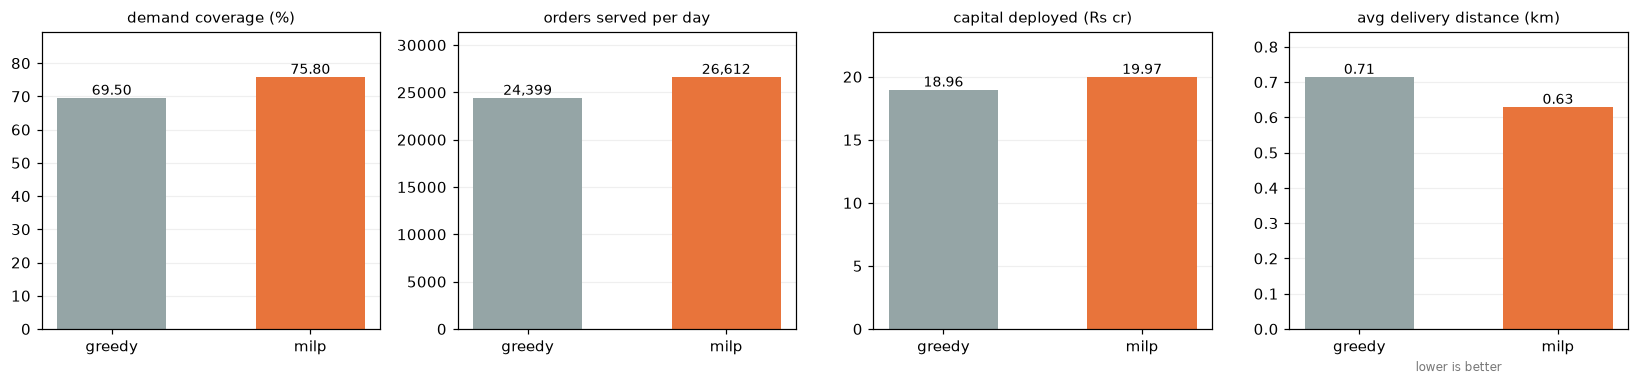

In [12]:
fig = plots.plot_comparison(comparison)
plt.show()

The optimizer serves about 2,200 more orders a day with the same budget. It does not get there by finding
better locations. Both plans run every store at full capacity, because the city wants more than the budget can
buy capacity for. So coverage depends only on how much capacity the money buys, and the optimizer buys more by
choosing nine cheaper sites where greedy chose six expensive ones. Deliveries also get a little shorter,
simply because there are more stores.

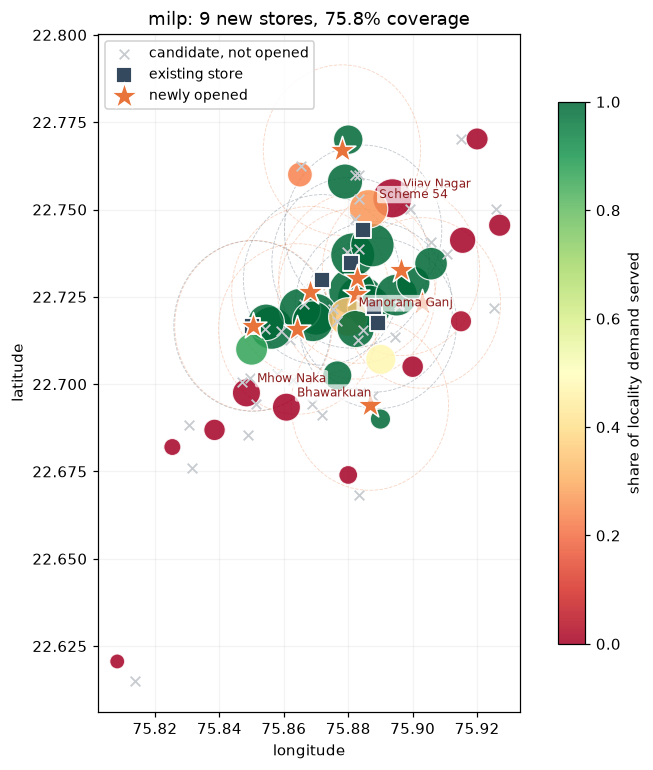

In [13]:
ax = plots.plot_network(optimal, radius_km=RADIUS_KM)
plt.show()

Green localities are fully served and red ones are not. With about 26,600 orders a day of capacity against
35,100 orders a day of demand, around 8,500 orders go unserved whichever sites are chosen. The only question is
which ones. The optimizer serves the orders it can deliver most cheaply and gives up the rest.

Vijay Nagar is the clearest example. Thirteen sites are within range of it and four of them are open, but every
one of those four is already full with orders from localities closer to it. Because the model penalises
distance, it spends capacity where deliveries are shortest.

### Who ends up unserved

Because the objective counts orders, it treats every order as worth the same, whether the basket is ₹420 or
₹720. That makes it worth checking which customers the optimizer gave up.

In [14]:
aov = localities["avg_order_value"].to_numpy(dtype=float)
tiers = localities["avg_household_income_tier"].to_numpy()

rows = []
for tier in ["low", "mid", "high"]:
    in_tier = tiers == tier
    rows.append({
        "income tier": tier,
        "demand": round(demand[in_tier].sum()),
        "greedy served %": round(100 * greedy.assignment[in_tier].sum() / demand[in_tier].sum(), 1),
        "optimizer served %": round(100 * optimal.assignment[in_tier].sum() / demand[in_tier].sum(), 1),
    })
by_tier = pd.DataFrame(rows).set_index("income tier")

revenue = lambda r: (r.assignment.sum(axis=1) * aov).sum() / 1e5
print(f"daily revenue served: greedy Rs {revenue(greedy):.1f} lakh, optimizer Rs {revenue(optimal):.1f} lakh")
by_tier

daily revenue served: greedy Rs 157.6 lakh, optimizer Rs 166.7 lakh


,demand,greedy served %,optimizer served %
income tier,,,
low,6114,56.3,49.4
mid,13511,40.4,77.5
high,15495,100.0,84.7


This is a real weakness. Greedy served every high-income locality in full. The optimizer serves about 85% of
high-income demand and drops Vijay Nagar entirely, and it uses the freed capacity to raise mid-income coverage
from about 40% to 78%. Revenue still goes up, because the extra orders outweigh the smaller baskets, but a
business would probably not want to lose its most valuable customers this way. The fix is to weight each
locality by what its orders are worth and by how loyal its customers are, so the optimizer stops treating
every order the same. The last section of this notebook makes that change and
measures what it does.

In [15]:
optimal.unserved_by_locality().head(8)

,locality_id,locality_name,demand,served,unserved,coverage_pct
0,21,Vijay Nagar,1393.1,0.0,1393.1,0.0
1,22,Scheme 54,1336.7,351.4,985.3,26.3
2,9,Manorama Ganj,1350.0,465.7,884.3,34.5
3,28,Mhow Naka,673.3,0.0,673.3,0.0
4,29,Bhawarkuan,671.8,0.0,671.8,0.0
5,17,Bengali Square,582.6,0.0,582.6,0.0
6,13,Tilak Nagar,789.4,375.4,414.0,47.6
7,19,Bicholi Mardana,388.4,0.0,388.4,0.0


## Does the answer depend on λ₁?

λ₁ is a judgement call. No single figure tells you how many orders one crore of capex should bring in. What I
can do is vary it and watch how the recommendation changes.

There is a natural reference point. A store costing ₹2.5 crore and serving about 1,800 orders a day breaks even
at around 720 orders per crore.

In [16]:
sweep = sensitivity_sweep(localities, facilities, distances, mask, demand, BUDGET,
                          lambda_values=[0, 100, 200, 300, 400, 500, 600, 700, 720, 800, 900, 1000, 1200])
sweep[["new_stores", "capex_cr", "demand_served", "coverage_pct", "avg_delivery_km"]]

,new_stores,capex_cr,demand_served,coverage_pct,avg_delivery_km
lambda_capex,,,,,
0,9,19.97,26612.0,75.8,0.629
100,9,19.97,26612.0,75.8,0.629
200,9,19.97,26612.0,75.8,0.629
300,9,19.97,26612.0,75.8,0.629
400,9,19.97,26612.0,75.8,0.629
500,9,19.97,26612.0,75.8,0.629
600,9,19.97,26612.0,75.8,0.629
700,9,19.97,26612.0,75.8,0.629
720,8,18.45,25426.0,72.4,0.575


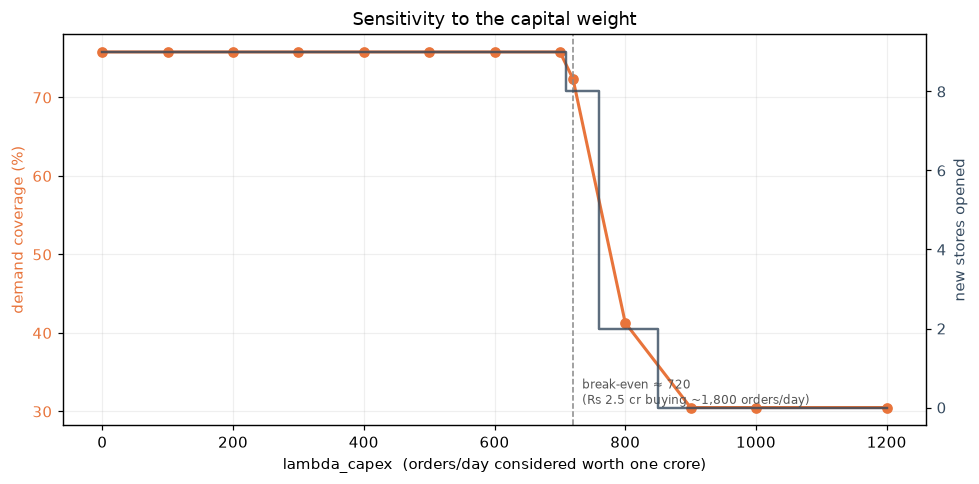

In [17]:
fig = plots.plot_sensitivity(sweep, breakeven=720)
plt.show()

For every value from 0 to 600 the recommendation stays exactly the same: nine stores and 75.8% coverage. It
first changes at 720, the break-even worked out above, and once λ₁ passes about 900 no store looks worth its
cost. So the result doesn't depend on picking the right λ₁. Any reasonable value below break-even gives the same
answer.

## Could a simpler method have done the job?

The LP relaxation is the same model, except the open/close choice can be any fraction between 0 and 1, as if
you could open 40% of a store. That version is much easier to solve, and its score is an upper limit on what
any whole-store plan can achieve. Comparing it with the MILP shows how much it costs to insist on whole stores.

In [18]:
gap = relaxation_gap(localities, facilities, distances, mask, demand, BUDGET)
print(f"MILP objective          : {gap['integer_objective']:,.1f}")
print(f"LP relaxation objective : {gap['relaxed_objective']:,.1f}")
print(f"gap                     : {gap['gap_pct']:.2f}%")

MILP objective          : 21,781.0
LP relaxation objective : 21,885.5
gap                     : 0.48%


The gap is under half a percent. That makes it tempting to skip the MILP altogether: solve the easy fractional
version, round each site to open or closed, and stop there. Below I test that.

In [19]:
rounding = round_relaxation(localities, facilities, distances, mask, demand, BUDGET)
print("sites the relaxation opens only partly:")
for site, share in sorted(rounding.attrs["fractional_sites"].items(), key=lambda t: -t[1]):
    print(f"  {site:>4}  {share * 100:5.1f}% open")
rounding

sites the relaxation opens only partly:
   S21   73.8% open
    S5   69.2% open
   S36   47.7% open
   S28   23.5% open
   S44   21.7% open
    S3   12.7% open
   S30   10.9% open


,new_stores,capex_cr,within_budget,coverage_pct
plan,,,,
MILP,9,19.97,True,75.8
"LP, round down",6,13.29,True,61.1
"LP, round to nearest",8,18.45,True,72.4
"LP, round up",13,30.95,False,96.2


Rounding doesn't work. The relaxation opens six sites fully and seven more partly, so its budget is spread
thinly across thirteen sites. Keeping only the fully opened sites gives 61.1% coverage, which is worse than
greedy. Rounding each site to the nearest whole value gives 72.4%, better than greedy but still behind the
MILP, and it leaves ₹1.5 crore unspent. Opening every partly opened site gives 96.2% coverage, but it costs
₹31 crore, which is far over budget.

So the small gap does not mean the easy version is good enough. It means the MILP's plan is very close to the
best possible score. Actually finding that plan, with whole stores and within budget, took the MILP.

## Festive demand

Blinkit has said publicly that capacity gets tight around Diwali, and the generated data shows the same thing:
the festive peak is about 2.5 times a normal day. So I re-ran the same model, with the same budget and
constraints, on scaled-up demand.

In [20]:
scenarios = scenario_analysis(localities, facilities, distances, mask, demand, BUDGET)
scenarios.drop(columns=["sites"])

,total_demand,new_stores,capex_cr,demand_served,unserved,coverage_pct,avg_delivery_km,capacity_util_pct
multiplier,,,,,,,,
1.0,35120,9,19.97,26612.0,8508,75.8,0.629,100.0
1.5,52681,9,19.98,26571.0,26110,50.4,0.528,100.0
2.0,70241,9,19.98,26571.0,43670,37.8,0.492,100.0
2.5,87801,9,19.98,26571.0,61230,30.3,0.471,100.0


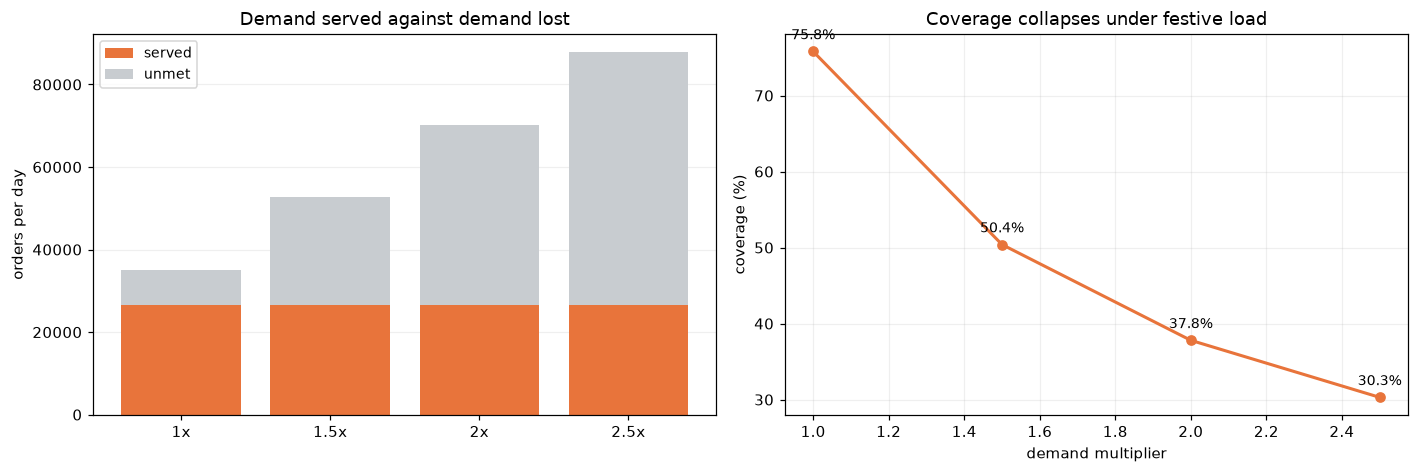

In [21]:
fig = plots.plot_scenarios(scenarios)
plt.show()

Orders served stay flat at every multiplier, with the same nine stores throughout. Capacity comes from the
budget and the budget doesn't grow, so once every store is full, rearranging the same stores can't add
capacity. Coverage falls from 75.8% to 30.3% while the plan itself stays the same. Building enough permanent
stores for the peak would leave most of them idle for the rest of the year. The realistic answer is temporary
capacity: extra staff, overflow space, and stock placed in stores before the festival starts.

Average delivery distance also falls as demand rises, from 0.63 km to 0.47 km. That is not an improvement. Full
stores serve their nearest localities first, so the orders that get dropped are the far-away ones. The metric
improves only because more customers are being turned away.

## Does forecasting demand change the answer?

Everything so far sites stores on average demand over the last 90 days, which assumes the future will look like
the past. Here I replace that with a forecast and check whether the answer changes.

The forecast is a ridge regression on day of week, log population density, income tier and lagged demand. The
lags use only earlier days. Using the same day's orders would be leakage: the model would look very accurate,
but only because it could see a number that won't exist yet when a real forecast is made. For the same reason
the train/test split is by date, not random. I compare the forecast against a seasonal-naive benchmark, which
predicts each day as the locality's average over the previous week.

In [22]:
from src.forecast import fit_forecast, forecast_demand_vector

fit = fit_forecast(pd.read_sql("SELECT * FROM demand", engine),
                   pd.read_sql("SELECT * FROM localities", engine))
print(f"train / test       : {fit['train_days']} / {fit['test_days']} days")
print(f"ridge MAE          : {fit['ridge_mae']:.1f} orders/day")
print(f"seasonal-naive MAE : {fit['naive_mae']:.1f} orders/day")
print(f"improvement        : {fit['improvement_pct']:.1f}%")
print()
print(fit["coefficients"].head(6).round(1).to_string())

train / test       : 69 / 14 days
ridge MAE          : 62.0 orders/day
seasonal-naive MAE : 85.1 orders/day
improvement        : 27.1%

lag_1d    608.2
dow_5     147.6
dow_4     134.8
dow_3     101.3
dow_2      91.5
dow_1      82.4


In [23]:
forecast = forecast_demand_vector(fit, localities)
optimal_forecast = optimize_network(localities, facilities, distances, mask,
                                    forecast["forecast_orders_per_day"].to_numpy(dtype=float),
                                    budget=BUDGET)

historical_sites = set(optimal.opened_sites()["facility_key"])
forecast_sites = set(optimal_forecast.opened_sites()["facility_key"])
print(f"sites from historical demand: {sorted(historical_sites)}")
print(f"sites from forecast demand  : {sorted(forecast_sites)}")
print(f"in common                   : {len(historical_sites & forecast_sites)} of {len(historical_sites)}")

sites from historical demand: ['S1', 'S12', 'S14', 'S20', 'S23', 'S38', 'S44', 'S5', 'S8']
sites from forecast demand  : ['S1', 'S12', 'S14', 'S20', 'S23', 'S38', 'S44', 'S5', 'S8']
in common                   : 9 of 9


The forecast is 27% more accurate than the benchmark, and the optimizer picks exactly the same nine sites with
it. Which sites get picked depends on how the localities rank against each other and on how much capacity each
site gives per rupee. A forecast that improves every locality's estimate by a similar amount leaves both of those
largely unchanged. So the recommendation holds up, and a better forecast would not have changed it.

## Counting money, not orders

Everything so far has maximised orders served, and the income-tier table showed where that leads. The optimizer
treats a ₹420 order and a ₹720 order as the same thing, and it gives up high-value customers whenever it can
pick up more orders elsewhere. It also treats a store as free to run once it is open, which it is not. This
section changes what the model is asked to maximise, from orders to money, and looks at how the answer changes.

It adds three things. Each order is weighted by its basket size. Each store pays a running cost for rent and
staff. And every plan gets a profit figure, so the comparison with greedy can be made in rupees.

### Loyalty

To let the model value customers who keep coming back, each locality now has a 90-day repeat rate: the share
of its customers who order again within 90 days. Like everything else at the locality level, it is synthetic,
since no retention data is public at this level of detail. I set it to rise with income, on the reasoning that
richer households are more likely to have made ten-minute delivery a habit, and added enough noise that
localities in the same tier differ.

In [24]:
loyalty = localities.groupby("avg_household_income_tier")["repeat_rate_90d"].agg(["mean", "min", "max"])
print(loyalty.round(3).to_string())
print()
print(localities.set_index("locality_name").loc[["Vijay Nagar", "Palasia", "Bhawarkuan", "Rau"],
      ["avg_household_income_tier", "avg_order_value", "repeat_rate_90d"]].to_string())

                            mean    min    max
avg_household_income_tier                     
high                       0.727  0.666  0.786
low                        0.511  0.442  0.608
mid                        0.622  0.525  0.703

              avg_household_income_tier  avg_order_value  repeat_rate_90d
locality_name                                                            
Vijay Nagar                        high           725.87            0.770
Palasia                            high           724.96            0.689
Bhawarkuan                          low           424.77            0.516
Rau                                 low           419.29            0.452


### Deriving the margin

To compute profit I need a contribution margin, meaning the share of each rupee of orders left after the cost
of goods, delivery, discounts and payment fees. Blinkit does not disclose one. It does disclose a target pre-tax
return on capital of about 41.7%, so I worked backwards from that. A typical store costs ₹2.5 crore and packs
about 1,800 orders a day. The question is what share of each rupee of orders it has to keep in order to earn
41.7% a year on that capex after paying its rent and staff.

Rent comes from the site data. Staff cost is the one input I had to assume outright: ₹4.5 lakh a month per
store, which pays for roughly fifteen to twenty pickers and packers plus a manager.

In [25]:
from src import economics as ec
from src.compare import compare_objectives, margin_sweep

econ = ec.default_economics(localities, facilities, demand)

candidates = facilities[~facilities["is_existing"]]
rent = candidates["rent_monthly"].median()
running_day = (rent + ec.STAFF_COST_MONTHLY) / ec.DAYS_PER_MONTH
target_day = ec.TARGET_PRETAX_ROCE * ec.CAPEX_PER_STORE / 365
aov = ec.mean_order_value(localities, demand)
nov_day = ec.TYPICAL_CAPACITY * aov

print(f"target profit per store : 41.7% x Rs 2.5 cr / 365       = Rs {target_day:>10,.0f} a day")
print(f"running cost per store  : (rent Rs {rent:,.0f} + staff Rs {ec.STAFF_COST_MONTHLY:,.0f}) / 30 = Rs {running_day:>10,.0f} a day")
print(f"NOV of a typical store  : 1,800 orders x Rs {aov:.0f}          = Rs {nov_day:>10,.0f} a day")
print(f"margin needed           : (target + running) / NOV   = {100 * econ.margin:.2f}%")

hurdle = ec.running_cost_in_orders(facilities, localities, demand, econ)
print()
print(f"orders a day a store needs just to cover its own rent and staff: about {np.median(hurdle[hurdle > 0]):.0f}")

target profit per store : 41.7% x Rs 2.5 cr / 365       = Rs     28,562 a day
running cost per store  : (rent Rs 157,956 + staff Rs 450,000) / 30 = Rs     20,265 a day
NOV of a typical store  : 1,800 orders x Rs 610          = Rs  1,097,331 a day
margin needed           : (target + running) / NOV   = 4.45%

orders a day a store needs just to cover its own rent and staff: about 747


Like store capacity, the margin is derived rather than disclosed, so it is only as reliable as the numbers it
comes from. If staff cost more than I assumed, a higher margin would be needed to reach the same return. For
that reason I also check every result below at margins between 3% and 8%.

The running cost matters more than it might seem. A store has to serve roughly 750 orders a day just to pay its
own rent and staff, out of a typical capacity of 1,800. A store in a quiet or low-value area can be full every
day and still lose money.

### Five plans, measured in rupees

Profit is measured against the six existing stores on their own. Each plan is credited with the extra
contribution its whole network earns over that baseline, minus the running costs of the stores it opens.
Counting only the orders served by a plan's new stores would miss a knock-on effect: when a new store takes over
an area, the existing store next door is freed up to serve other customers.

The plans are:

- **greedy, orders** and **MILP, orders**: the original two, which maximise orders served;
- **greedy, profit** and **MILP, profit**: orders weighted by basket size, with running costs. For the MILP this
  makes the objective exactly equal to profit;
- **MILP, loyalty**: orders weighted by basket size times repeat rate, with running costs.

In [26]:
table = compare_objectives(localities, facilities, distances, mask, demand, BUDGET, econ)
table

,new_stores,capex_cr,coverage_pct,low_pct,mid_pct,high_pct,vijay_nagar_pct,profit_cr_per_year,payback_years,roce_pct
plan,,,,,,,,,,
"greedy, orders",6,18.96,69.5,56.3,40.4,100.0,100,8.65,2.19,45.6
"MILP, orders",9,19.97,75.8,49.4,77.5,84.7,0,8.16,2.45,40.8
"greedy, profit",6,18.91,68.6,19.7,54.7,100.0,100,8.88,2.13,47.0
"MILP, profit",7,19.87,73.3,10.5,71.1,100.0,100,10.02,1.98,50.5
"MILP, loyalty",7,19.39,72.2,0.0,73.0,100.0,100,9.71,2.00,50.1


The first thing this table shows is awkward for the result earlier in the notebook. The original
order-counting MILP serves about 2,200 more orders a day than greedy, but it earns less money: ₹8.16 crore a
year against ₹8.65 crore. Each of its three extra stores has rent and staff to pay, and it won part of those
extra orders by giving up high-value customers, Vijay Nagar among them. The earlier headline holds for orders
but not for profit.

When the MILP is asked to maximise profit instead, it opens 7 stores and serves 73.3% of demand. It keeps every
high-income customer, Vijay Nagar included, and earns ₹10.02 crore a year, against ₹8.88 crore for a greedy
heuristic with the same goal. That is a 50.5% return on the capital it spends. The margin was derived from a
41.7% target, so landing close to it suggests the setup is sensible.

### Does the ranking hold at other margins?

The margin is the least certain number in this section, so I check whether the ranking of the plans changes
when it moves.

In [27]:
sweep = margin_sweep(localities, facilities, distances, mask, demand, BUDGET,
                     [0.03, econ.margin, 0.06, 0.08])
sweep

,"greedy, orders","MILP, orders","greedy, profit","MILP, profit","MILP, loyalty"
margin_pct,,,,,
3.00,4.28,3.31,4.45,5.05,3.93
4.45,8.65,8.16,8.88,10.02,9.71
6.00,13.31,13.34,13.65,15.54,14.96
8.00,19.34,20.03,19.81,22.75,22.64


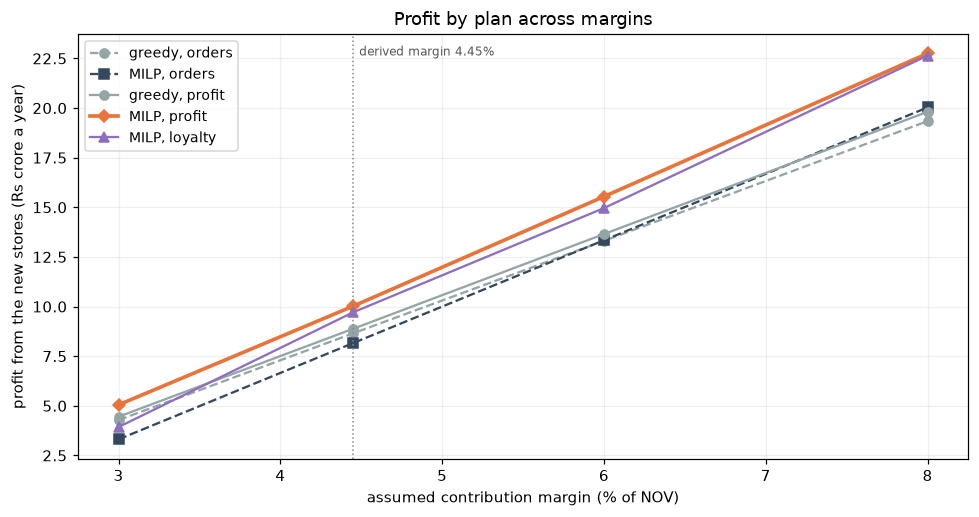

In [28]:
fig = plots.plot_margin_sweep(sweep, derived_margin_pct=100 * econ.margin)
plt.show()

The profit MILP earns the most at every margin, and that is guaranteed rather than lucky. Its objective is
profit, so no plan that fits the budget can earn more, and a test in the project checks this at each of the
margins above. The order-counting MILP, by contrast, only beats order-counting greedy once the margin reaches
about 6%. Below that, each extra order earns too little to pay for the extra stores needed to serve it.

### What valuing loyalty costs

The loyalty model weights each order by basket size and by how loyal customers in that area are. The aim was
to stop the optimizer abandoning valuable areas like Vijay Nagar, and it does keep Vijay Nagar. But so does the
profit model, because Vijay Nagar's baskets are large enough on their own.

What loyalty adds on top is a stronger push away from low-income areas, where customers both spend less and
come back less often. At the derived margin the loyalty model serves none of the low-income demand, against
10.5% under the profit model, and it earns about ₹0.3 crore a year less. At a 3% margin it drops to five stores
and earns less than greedy as well.

The loyalty model is therefore a bet. It gives up some profit now on the assumption that loyal customers will
be worth more later than one day's contribution suggests. Whether that bet pays off can only be judged with
real retention data, which this project doesn't have. With synthetic loyalty numbers, I would recommend the
profit model and treat the loyalty model as a measure of what favouring loyal customers would cost.

## Limitations

The data is synthetic. The totals are calibrated to disclosed figures, but everything at the locality level,
loyalty included, is made up. These results show how the method behaves on realistic-looking data and are not
a recommendation for Indore.

The profit figures depend on two numbers I don't have. The margin is derived from the disclosed return target,
but that derivation needs an assumed staff cost, and it treats return on capital as return on capex, leaving
out working capital. The margin sweep shows the recommendation holds from 3% to 8%, but the rupee amounts are
illustrative.

Weighting by value pushes service towards richer areas. Low-income localities get about 10% of their demand
served under the profit model and none under the loyalty model. That follows directly from the objective. A
business that wanted a presence in every area would have to add a minimum level of service per locality, and
accept some loss of profit for it.

The profit model sets the distance weight to zero, so a longer delivery costs nothing extra. In reality rider
cost goes up with distance, which would favour stores closer to their customers.

Distance is measured from the centre of each locality, which is why the model reports an average of about
0.63 km against a peer average of 1.7 to 1.8 km. Road distances would make every trip longer and put fewer
localities within reach of each site.

Capacity is a single number per day. Real stores get most of their orders in the evening, so a store that
looks fine over a whole day can still fall behind at 7 pm.

The model has no competition in it. When a new store opens near an existing one, it only shifts demand between
the two. No customer switches to a rival, and no rival reacts to the expansion.

## Summary

Counting orders, the MILP clearly beat greedy. With ₹20 crore it opened 9 stores and served 75.8% of demand,
against greedy's 6 stores and 69.5%, because it bought capacity more cheaply. Counting money reverses that.
Once stores pay rent and staff, the order-counting MILP earns slightly less than greedy: its extra stores cost
more to run than their orders bring in, and it gave up high-value customers to win those orders.

Asked to maximise profit directly, the MILP opens 7 stores, serves 73.3% of demand, keeps every high-income
customer, and earns about ₹10.0 crore a year, against ₹8.9 crore for greedy with the same goal. It earns the
most at every margin tested, as it has to, since profit is exactly what it maximises. Adding loyalty on top
costs about ₹0.3 crore a year and removes the remaining service to low-income areas.

Two findings hold in every version. At festive demand, coverage falls to about 30% and no rearrangement of the
same budget helps, which argues for temporary capacity during peaks. And rounding the LP relaxation does not
give a usable plan, so solving the MILP was worth it.

The broader lesson is about the objective. The same solver, on the same data, gave a different recommendation
depending on whether it was told to count orders or money. Deciding what to maximise mattered more than how
well it was maximised.